# Real road obstacle detector — training notebook

The car's camera must recognise **real obstacles on the road** in real time. We use two YOLO models that run side by side in the dashboard:

| Model | Detects | Trained on | How |
|---|---|---|---|
| **Road users** | pedestrian, cyclist, vehicle, animal | **COCO 2017** (118k real images) | YOLO26n COCO-pretrained weights, used as-is |
| **Road hazards** | pothole, cone, barrier, roadwork sign | **2 real dashcam datasets** (below) | YOLO26s **fine-tuned overnight in this notebook** |

### Datasets (real, open licences)

| Dataset | Content | Licence | Source |
|---|---|---|---|
| **Potholes under challenging conditions** — Bučko et al., *Sensors* 22(22):8878, 2022 | 2,099 Full-HD **dashcam** frames, 11 drives (clear, sunset, evening, night, rain), YOLO labels | CC BY 4.0 | [figshare 10.6084/m9.figshare.21214400](https://doi.org/10.6084/m9.figshare.21214400) |
| **ROADWork** — Ghosh et al., ICCV 2025 (Carnegie Mellon University) | 7,416 annotated 1920×1080 **dashcam** frames of work zones in 18 US cities: cones, drums, barricades, barriers, fences, signs… | ODC-By 1.0 | [huggingface.co/datasets/anuragxel/roadwork-dataset](https://huggingface.co/datasets/anuragxel/roadwork-dataset) |

Class mapping for the hazards model:

| Our class | Pothole dataset | ROADWork categories |
|---|---|---|
| `pothole` | pothole | — |
| `cone` | — | Cone, Tubular Marker |
| `barrier` | — | Drum, Barricade, Barrier, Fence, Vertical Panel |
| `roadwork_sign` | — | Temporary Traffic Control Sign, Arrow Board, TTC Message Board |

Workers, work vehicles and police are **not** in the hazards model: the road-users model already detects people and vehicles.

### Pipeline
1. Download only the images we need straight out of the remote zip archives (HTTP range requests — the full archives are 11 GB).
2. Split **by time / by place** so near-identical frames never land in both train and test.
3. Fine-tune YOLO on the GPU, evaluate on the held-out **test** split.
4. Export both models to **ONNX** for the dashboard (runs on CPU in real time) and write the real metrics to `models/registry.json`.
5. Cut short **real dashcam demo clips** (Wikimedia Commons, free licences) for the live demo.

### ▶ How to run it (directly from this notebook)
About **8.5 hours**: downloads ~20 min (≈ 8 GB, only the first time), training **8 h** (`TRAIN_HOURS`), evaluation + export + demo clips ~10 min.

**Once** — the GPU and all the libraries live in the Docker `trainer` container, so the notebook runs on its kernel:
1. In a terminal: `docker compose --profile train up -d trainer`
2. Top right of this notebook: **Select Kernel → Select Another Kernel… → Existing Jupyter Server…** → paste `http://localhost:8888/?token=smartcar` → name it `smartcar-docker` → **Python 3 (ipykernel)**. VS Code remembers it.

**Every run:** click **Run All** (▶▶ in the toolbar), or ▶ on each cell from top to bottom. Every cell prints its progress live; the training cell shows one progress bar per epoch and the validation precision / recall / mAP after each epoch.

Tips for the night: keep the laptop plugged in and awake (`powercfg /change standby-timeout-ac 0`), stop the dashboard and other containers (`docker compose stop dashboard`). If VS Code is closed, training **keeps running** in the container — open `monitor_training.ipynb` (same kernel) to follow it. If the run is interrupted, set `RESUME = True` and Run All again.

In [1]:
# Parameters — overnight configuration (papermill / run_training.ps1 can override them:  -p TRAIN_HOURS 8)
TRAIN_HOURS = 8.0             # training budget (a full night): Ultralytics fits the epochs and LR schedule to it
MODEL = "yolo26s.pt"          # hazards model: YOLO26 *small* (more accurate than nano), COCO-pretrained start
USERS_MODEL = "yolo26n.pt"    # road-users model (COCO, used as-is): nano keeps the dashboard real time on CPU
IMGSZ = 640
BATCH = 4                     # YOLO26s fits in 2.6 GB at 4 (AMP is off on GTX 16xx); gradients are accumulated to 64
WORKERS = 4
PATIENCE = 100                # early stopping effectively off: use the whole time budget
POTHOLE_FRAME_STEP = 1        # all pothole frames
ROADWORK_TRAIN = 5000         # images from the ROADWork train split (5,226 contain our classes)
ROADWORK_VAL = 600            # ... and from its geographically separate val split
ROADWORK_TEST = 600
DOWNLOAD_WORKERS = 8
SAVE_MAX_SIDE = 960           # images are stored downscaled (faster loading, smaller disk)
SEED = 0
RESUME = False                # True = continue an interrupted run from training/runs/road_hazards/weights/last.pt
FETCH_DEMO_VIDEOS = True

In [2]:
# Check that this notebook runs on the Docker kernel (GPU + libraries are in the trainer container)
from pathlib import Path
if not Path("/workspace/training").exists() or not Path("/datasets").exists():
    raise SystemExit(
        "Wrong kernel: this is not the Docker trainer.\n"
        "1) terminal: docker compose --profile train up -d trainer\n"
        "2) top right: Select Kernel -> Select Another Kernel... -> Existing Jupyter Server... -> "
        "http://localhost:8888/?token=smartcar -> Python 3 (ipykernel)")
print("OK — running on the Docker trainer kernel")

OK — running on the Docker trainer kernel


In [3]:
import ast, collections, json, os, random, shutil, subprocess, sys, time, urllib.request, zipfile
from datetime import date
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import ultralytics
from IPython.display import Image, display
from ultralytics import YOLO

PROJECT = Path("/workspace")                 # the project folder (mounted)
DATA = Path("/datasets")                     # Docker volume: raw downloads + prepared dataset
RAW, DS = DATA / "raw", DATA / "road_hazards"
MODELS, RUNS, DEMO = PROJECT / "models", PROJECT / "training" / "runs", PROJECT / "demo" / "videos"
for p in (RAW, DS, MODELS, RUNS, DEMO):
    p.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(PROJECT / "training"))
from remote_zip import RemoteZip, download

CLASSES = ["pothole", "cone", "barrier", "roadwork_sign"]
random.seed(SEED)
print(f"ultralytics {ultralytics.__version__} · torch {torch.__version__} · CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    p = torch.cuda.get_device_properties(0)
    print(f"GPU: {p.name} · {p.total_memory / 1e9:.1f} GB")
DEVICE = 0 if torch.cuda.is_available() else "cpu"

ultralytics 8.4.184 · torch 2.14.1+cu132 · CUDA available: True
GPU: NVIDIA GeForce GTX 1650 Ti · 4.3 GB


## 1 · Potholes dataset (dashcam, 5 light / weather conditions)
Each of the 11 drives is cut in time: first 80 % of frames → train, next 10 % → val, last 10 % → test, with a gap of a few frames between blocks so no near-duplicate frame is shared.

In [4]:
POTHOLE_URL = "https://ndownloader.figshare.com/files/37622126"
rz = RemoteZip(POTHOLE_URL)
images = sorted(n for n in rz.namelist() if n.lower().endswith((".jpg", ".jpeg", ".png")))
names = set(rz.namelist())

def drive_of(member):                      # e.g. Night/Vid_Pr
    p = Path(member)
    return p.parent.name + "/" + "_".join(p.stem.split("_")[:2])

by_drive = collections.defaultdict(list)
for n in images:
    if str(Path(n).with_suffix(".txt")) in names:
        by_drive[drive_of(n)].append(n)

GAP = 5
pothole_split = {}
for drive, frames in sorted(by_drive.items()):
    frames.sort()
    n = len(frames)
    a, b = int(n * 0.8), int(n * 0.9)
    blocks = {"train": frames[:a - GAP], "val": frames[a:b - GAP], "test": frames[b:]}
    for split, fr in blocks.items():
        for f in fr[::POTHOLE_FRAME_STEP]:
            pothole_split[f] = split
print(f"{len(by_drive)} drives · {len(pothole_split)} frames kept:",
      collections.Counter(pothole_split.values()))

11 drives · 1989 frames kept: Counter({'train': 1619, 'test': 215, 'val': 155})


In [5]:
members = list(pothole_split) + [str(Path(n).with_suffix(".txt")) for n in pothole_split]
t0 = time.time()
rz.extract_many(members, RAW / "potholes", workers=DOWNLOAD_WORKERS, flatten=False)
print(f"done in {time.time() - t0:.0f}s")

  50/1970 files · 33/491 MB · 4.1 MB/s
  100/1970 files · 62/491 MB · 5.1 MB/s
  150/1970 files · 90/491 MB · 5.6 MB/s
  200/1970 files · 118/491 MB · 5.9 MB/s
  250/1970 files · 150/491 MB · 6.2 MB/s
  300/1970 files · 182/491 MB · 4.8 MB/s
  350/1970 files · 210/491 MB · 4.6 MB/s
  400/1970 files · 237/491 MB · 4.5 MB/s
  450/1970 files · 266/491 MB · 4.7 MB/s
  500/1970 files · 296/491 MB · 4.8 MB/s
  550/1970 files · 318/491 MB · 4.9 MB/s
  600/1970 files · 337/491 MB · 5.0 MB/s
  650/1970 files · 353/491 MB · 4.6 MB/s
  700/1970 files · 365/491 MB · 4.3 MB/s
  750/1970 files · 376/491 MB · 4.3 MB/s
  800/1970 files · 397/491 MB · 4.3 MB/s
  850/1970 files · 423/491 MB · 4.4 MB/s
  900/1970 files · 449/491 MB · 4.5 MB/s
  950/1970 files · 474/491 MB · 4.6 MB/s
  1000/1970 files · 491/491 MB · 4.6 MB/s
  1050/1970 files · 491/491 MB · 4.6 MB/s
  1100/1970 files · 491/491 MB · 4.5 MB/s
  1150/1970 files · 491/491 MB · 4.4 MB/s
  1200/1970 files · 491/491 MB · 4.0 MB/s
  1250/1970 fil

In [6]:
def save_image(src, dst):
    img = cv2.imread(str(src))
    h, w = img.shape[:2]
    s = SAVE_MAX_SIDE / max(h, w)
    if s < 1:
        img = cv2.resize(img, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA)
    dst.parent.mkdir(parents=True, exist_ok=True)
    cv2.imwrite(str(dst), img, [cv2.IMWRITE_JPEG_QUALITY, 90])

shutil.rmtree(DS, ignore_errors=True)   # rebuilt from the raw downloads every run (same seed -> same dataset)
for split in ("train", "val", "test"):
    (DS / "images" / split).mkdir(parents=True, exist_ok=True)
    (DS / "labels" / split).mkdir(parents=True, exist_ok=True)

n_boxes = 0
for member, split in pothole_split.items():
    src = RAW / "potholes" / member
    stem = "pothole_" + drive_of(member).replace("/", "_") + "_" + Path(member).stem.split("_")[-1]
    dst = DS / "images" / split / f"{stem}.jpg"
    if not dst.exists():
        save_image(src, dst)
    lines = [l.split() for l in (src.with_suffix(".txt")).read_text().splitlines() if l.strip()]
    lines = [["0"] + l[1:5] for l in lines if len(l) >= 5]          # class 0 = pothole
    n_boxes += len(lines)
    (DS / "labels" / split / f"{stem}.txt").write_text("\n".join(" ".join(l) for l in lines))
print(f"potholes ready: {len(pothole_split)} images, {n_boxes} boxes")

potholes ready: 1989 images, 3483 boxes


## 2 · ROADWork dataset (work zones, 18 US cities)
We use the official **GPS split** (train and val come from different places) and sample images that contain at least one of our classes.

In [7]:
ROADWORK = "https://huggingface.co/datasets/anuragxel/roadwork-dataset/resolve/main/"
ann_zip = RAW / "roadwork_annotations.zip"
if not ann_zip.exists():
    download(ROADWORK + "annotations.zip", ann_zip)
az = zipfile.ZipFile(ann_zip)

CAT_MAP = {"Cone": 1, "Tubular Marker": 1,
           "Drum": 2, "Barricade": 2, "Barrier": 2, "Fence": 2, "Vertical Panel": 2,
           "Temporary Traffic Control Sign": 3, "Arrow Board": 3, "Temporary Traffic Control Message Board": 3}

def parse(v):
    return ast.literal_eval(v) if isinstance(v, str) else v

def load_split(name):
    d = json.loads(az.read(f"annotations/instances_{name}.json"))
    cats = {str(c["id"]): c["name"] for c in d["categories"]}
    imgs = {str(i["id"]): i for i in d["images"]}
    boxes = collections.defaultdict(list)
    for a in d["annotations"]:
        cls = CAT_MAP.get(cats[str(a["category_id"])])
        if cls is None or str(a.get("iscrowd", "0")) == "1":
            continue
        x, y, w, h = parse(a["bbox"])
        im = imgs[str(a["image_id"])]
        W, H = float(im["width"]), float(im["height"])
        if w < 3 or h < 3:
            continue
        boxes[im["file_name"]].append((cls, (x + w / 2) / W, (y + h / 2) / H, w / W, h / H))
    return boxes

rw_train, rw_val = load_split("train_gps_split"), load_split("val_gps_split")
val_names = sorted(rw_val)
random.shuffle(val_names)
roadwork_split = {f: "train" for f in random.sample(sorted(rw_train), min(ROADWORK_TRAIN, len(rw_train)))}
roadwork_split.update({f: "val" for f in val_names[:ROADWORK_VAL]})
roadwork_split.update({f: "test" for f in val_names[ROADWORK_VAL:ROADWORK_VAL + ROADWORK_TEST]})
roadwork_boxes = {**rw_train, **rw_val}
print(f"ROADWork: {len(rw_train)} train / {len(rw_val)} val images with our classes → using",
      collections.Counter(roadwork_split.values()))

ROADWork: 5226 train / 2086 val images with our classes → using Counter({'train': 5000, 'val': 600, 'test': 600})


In [8]:
iz = RemoteZip(ROADWORK + "images.zip")
member_of = {Path(n).name: n for n in iz.namelist() if n.lower().endswith(".jpg")}
wanted = [member_of[f] for f in roadwork_split if f in member_of]
print(f"downloading {len(wanted)} images out of {len(member_of)} in the 10.6 GB archive…")
t0 = time.time()
iz.extract_many(wanted, RAW / "roadwork", workers=DOWNLOAD_WORKERS)
print(f"done in {time.time() - t0:.0f}s")

for fname, split in roadwork_split.items():
    src = RAW / "roadwork" / fname
    if not src.exists():
        continue
    stem = "roadwork_" + Path(fname).stem
    dst = DS / "images" / split / f"{stem}.jpg"
    if not dst.exists():
        save_image(src, dst)
    (DS / "labels" / split / f"{stem}.txt").write_text(
        "\n".join(f"{c} {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}" for c, cx, cy, w, h in roadwork_boxes[fname]))
print("ROADWork ready")

downloading 6200 images out of 8549 in the 10.6 GB archive…
  50/4607 files · 32/5792 MB · 3.1 MB/s
  100/4607 files · 64/5792 MB · 4.0 MB/s
  150/4607 files · 134/5792 MB · 5.6 MB/s
  200/4607 files · 196/5792 MB · 5.0 MB/s
  250/4607 files · 274/5792 MB · 5.6 MB/s
  300/4607 files · 331/5792 MB · 6.0 MB/s
  350/4607 files · 400/5792 MB · 6.5 MB/s
  400/4607 files · 463/5792 MB · 6.4 MB/s
  450/4607 files · 540/5792 MB · 5.9 MB/s
  500/4607 files · 592/5792 MB · 6.1 MB/s
  550/4607 files · 664/5792 MB · 6.3 MB/s
  600/4607 files · 730/5792 MB · 6.5 MB/s
  650/4607 files · 803/5792 MB · 6.1 MB/s
  700/4607 files · 878/5792 MB · 6.2 MB/s
  750/4607 files · 949/5792 MB · 6.4 MB/s
  800/4607 files · 1014/5792 MB · 6.6 MB/s
  850/4607 files · 1095/5792 MB · 6.3 MB/s
  900/4607 files · 1169/5792 MB · 6.4 MB/s
  950/4607 files · 1237/5792 MB · 6.5 MB/s
  1000/4607 files · 1311/5792 MB · 6.7 MB/s
  1050/4607 files · 1379/5792 MB · 6.3 MB/s
  1100/4607 files · 1451/5792 MB · 6.4 MB/s
  1150/46

## 3 · Final dataset

images: {'train': 6324, 'val': 755, 'test': 815}
train: {'cone': 19638, 'roadwork_sign': 7211, 'barrier': 21914, 'pothole': 2670}
  val: {'roadwork_sign': 508, 'cone': 2615, 'barrier': 1868, 'pothole': 189}
 test: {'barrier': 2087, 'cone': 2376, 'pothole': 299, 'roadwork_sign': 489}


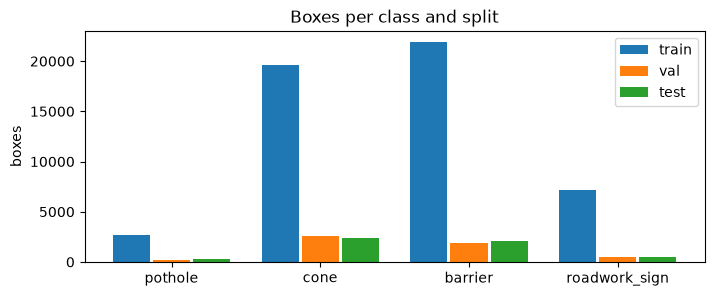

In [9]:
(DS / "data.yaml").write_text(
    f"path: {DS}\ntrain: images/train\nval: images/val\ntest: images/test\n"
    f"names:\n" + "".join(f"  {i}: {c}\n" for i, c in enumerate(CLASSES)))

stats = {s: collections.Counter() for s in ("train", "val", "test")}
n_img = {}
for split in stats:
    files = list((DS / "labels" / split).glob("*.txt"))
    n_img[split] = len(files)
    for f in files:
        for line in f.read_text().splitlines():
            if line.strip():
                stats[split][CLASSES[int(line.split()[0])]] += 1
print("images:", n_img)
for s in stats:
    print(f"{s:>5}:", dict(stats[s]))

fig, ax = plt.subplots(figsize=(8, 3))
x = np.arange(len(CLASSES))
for i, s in enumerate(stats):
    ax.bar(x + (i - 1) * 0.27, [stats[s][c] for c in CLASSES], width=0.25, label=s)
ax.set_xticks(x, CLASSES); ax.set_ylabel("boxes"); ax.legend(); ax.set_title("Boxes per class and split")
plt.show()

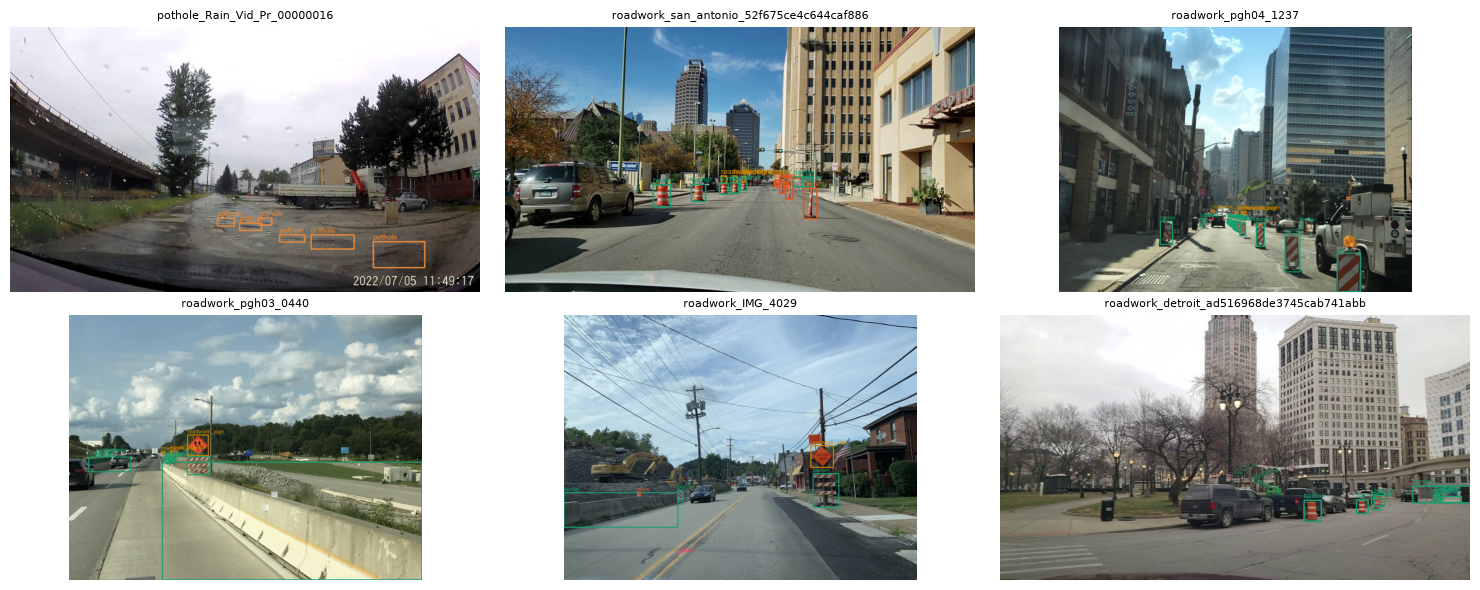

In [10]:
# A few training images with their labels
colors = [(57, 135, 229), (38, 89, 217), (112, 158, 25), (0, 133, 201)]
samples = random.sample(sorted((DS / "images" / "train").glob("*.jpg")), 6)
fig, axes = plt.subplots(2, 3, figsize=(15, 6))
for ax, path in zip(axes.flat, samples):
    img = cv2.imread(str(path)); h, w = img.shape[:2]
    for line in (DS / "labels" / "train" / (path.stem + ".txt")).read_text().splitlines():
        c, cx, cy, bw, bh = map(float, line.split())
        x1, y1, x2, y2 = int((cx - bw / 2) * w), int((cy - bh / 2) * h), int((cx + bw / 2) * w), int((cy + bh / 2) * h)
        cv2.rectangle(img, (x1, y1), (x2, y2), colors[int(c)], 2)
        cv2.putText(img, CLASSES[int(c)], (x1, max(12, y1 - 4)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, colors[int(c)], 1)
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax.set_title(path.stem[:40], fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

## 4 · Fine-tune on the GPU (overnight)
Starting from COCO-pretrained weights (transfer learning). Training runs for `TRAIN_HOURS`: after the first epoch Ultralytics measures how long an epoch takes and sets the number of epochs (and the learning-rate schedule) to fill the budget. It prints one progress bar per epoch with the losses, then the validation precision / recall / mAP.

`last.pt` is saved after every epoch: if the night is interrupted (reboot, power…), set `RESUME = True` and run again.

Ultralytics 8.4.184 🚀 Python-3.12.3 torch-2.14.1+cu132 CUDA:0 (NVIDIA GeForce GTX 1650 Ti, 4096MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/datasets/road_hazards/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=300, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=road_hazards, nbs=64, nms=None, opset=None

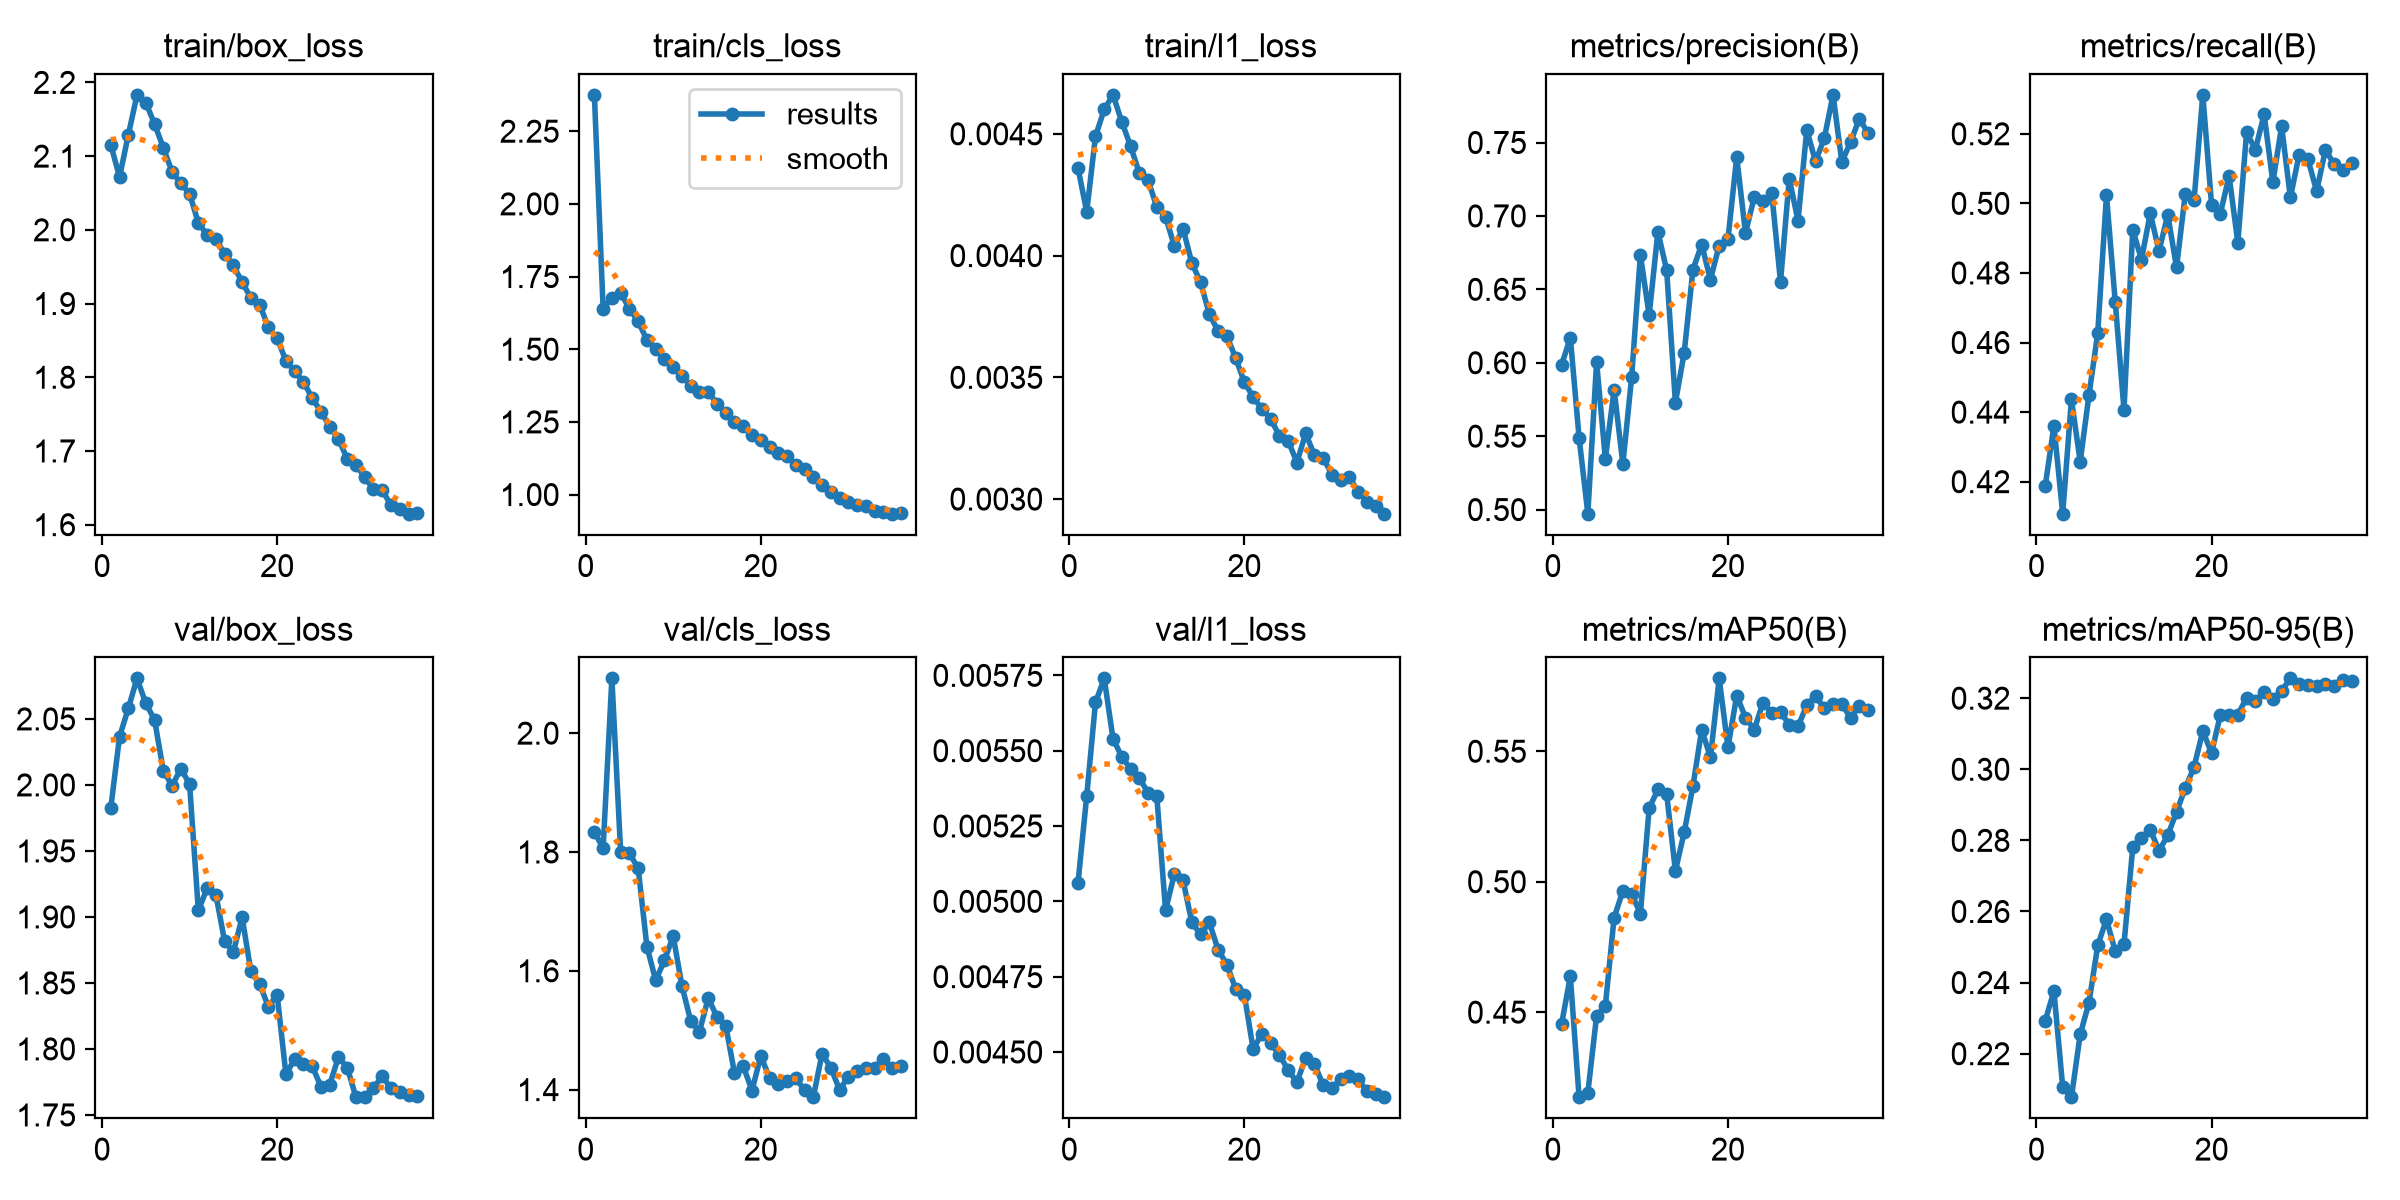

In [11]:
LAST = RUNS / "road_hazards" / "weights" / "last.pt"
t0 = time.time()
if RESUME and LAST.exists():
    print(f"resuming from {LAST}")
    model = YOLO(LAST)
    model.train(resume=True)
else:
    model = YOLO(MODEL)
    model.train(data=str(DS / "data.yaml"), time=TRAIN_HOURS, epochs=300, imgsz=IMGSZ, batch=BATCH,
                workers=WORKERS, device=DEVICE, patience=PATIENCE, seed=SEED, cos_lr=True, close_mosaic=10,
                plots=True, project=str(RUNS), name="road_hazards", exist_ok=True)
TRAIN_MINUTES = (time.time() - t0) / 60
EPOCHS_DONE = model.trainer.epoch + 1
BEST = RUNS / "road_hazards" / "weights" / "best.pt"
print(f"training took {TRAIN_MINUTES / 60:.1f} h · {EPOCHS_DONE} epochs · best weights: {BEST}")
display(Image(filename=str(RUNS / "road_hazards" / "results.png"), width=1000))

## 5 · Evaluate on the held-out test split (never seen during training)

Ultralytics 8.4.184 🚀 Python-3.12.3 torch-2.14.1+cu132 CUDA:0 (NVIDIA GeForce GTX 1650 Ti, 4096MiB)
YOLO26s summary (fused): 120 layers, 9,466,728 parameters, 0 gradients, 20.8 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 5.2±4.9 ms, read: 11.5±8.3 MB/s, size: 122.4 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /datasets/road_hazards/labels/test... 815 images, 70 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 815/815 424.1it/s 1.9s0.1s
val: /datasets/road_hazards/images/test/roadwork_houston_3c5d946bb34d48649217ba001b874b17_000000_07530.jpg: 8 duplicate labels removed
val: /datasets/road_hazards/images/test/roadwork_houston_3c5d946bb34d48649217ba001b874b17_000000_13830.jpg: 14 duplicate labels removed
val: /datasets/road_hazards/images/test/roadwork_houston_43adb415eb0244ac8c5012fe05c623ba_000000_10830.jpg: 8 duplicate labels removed
val: /datasets/road_hazards/images/tes

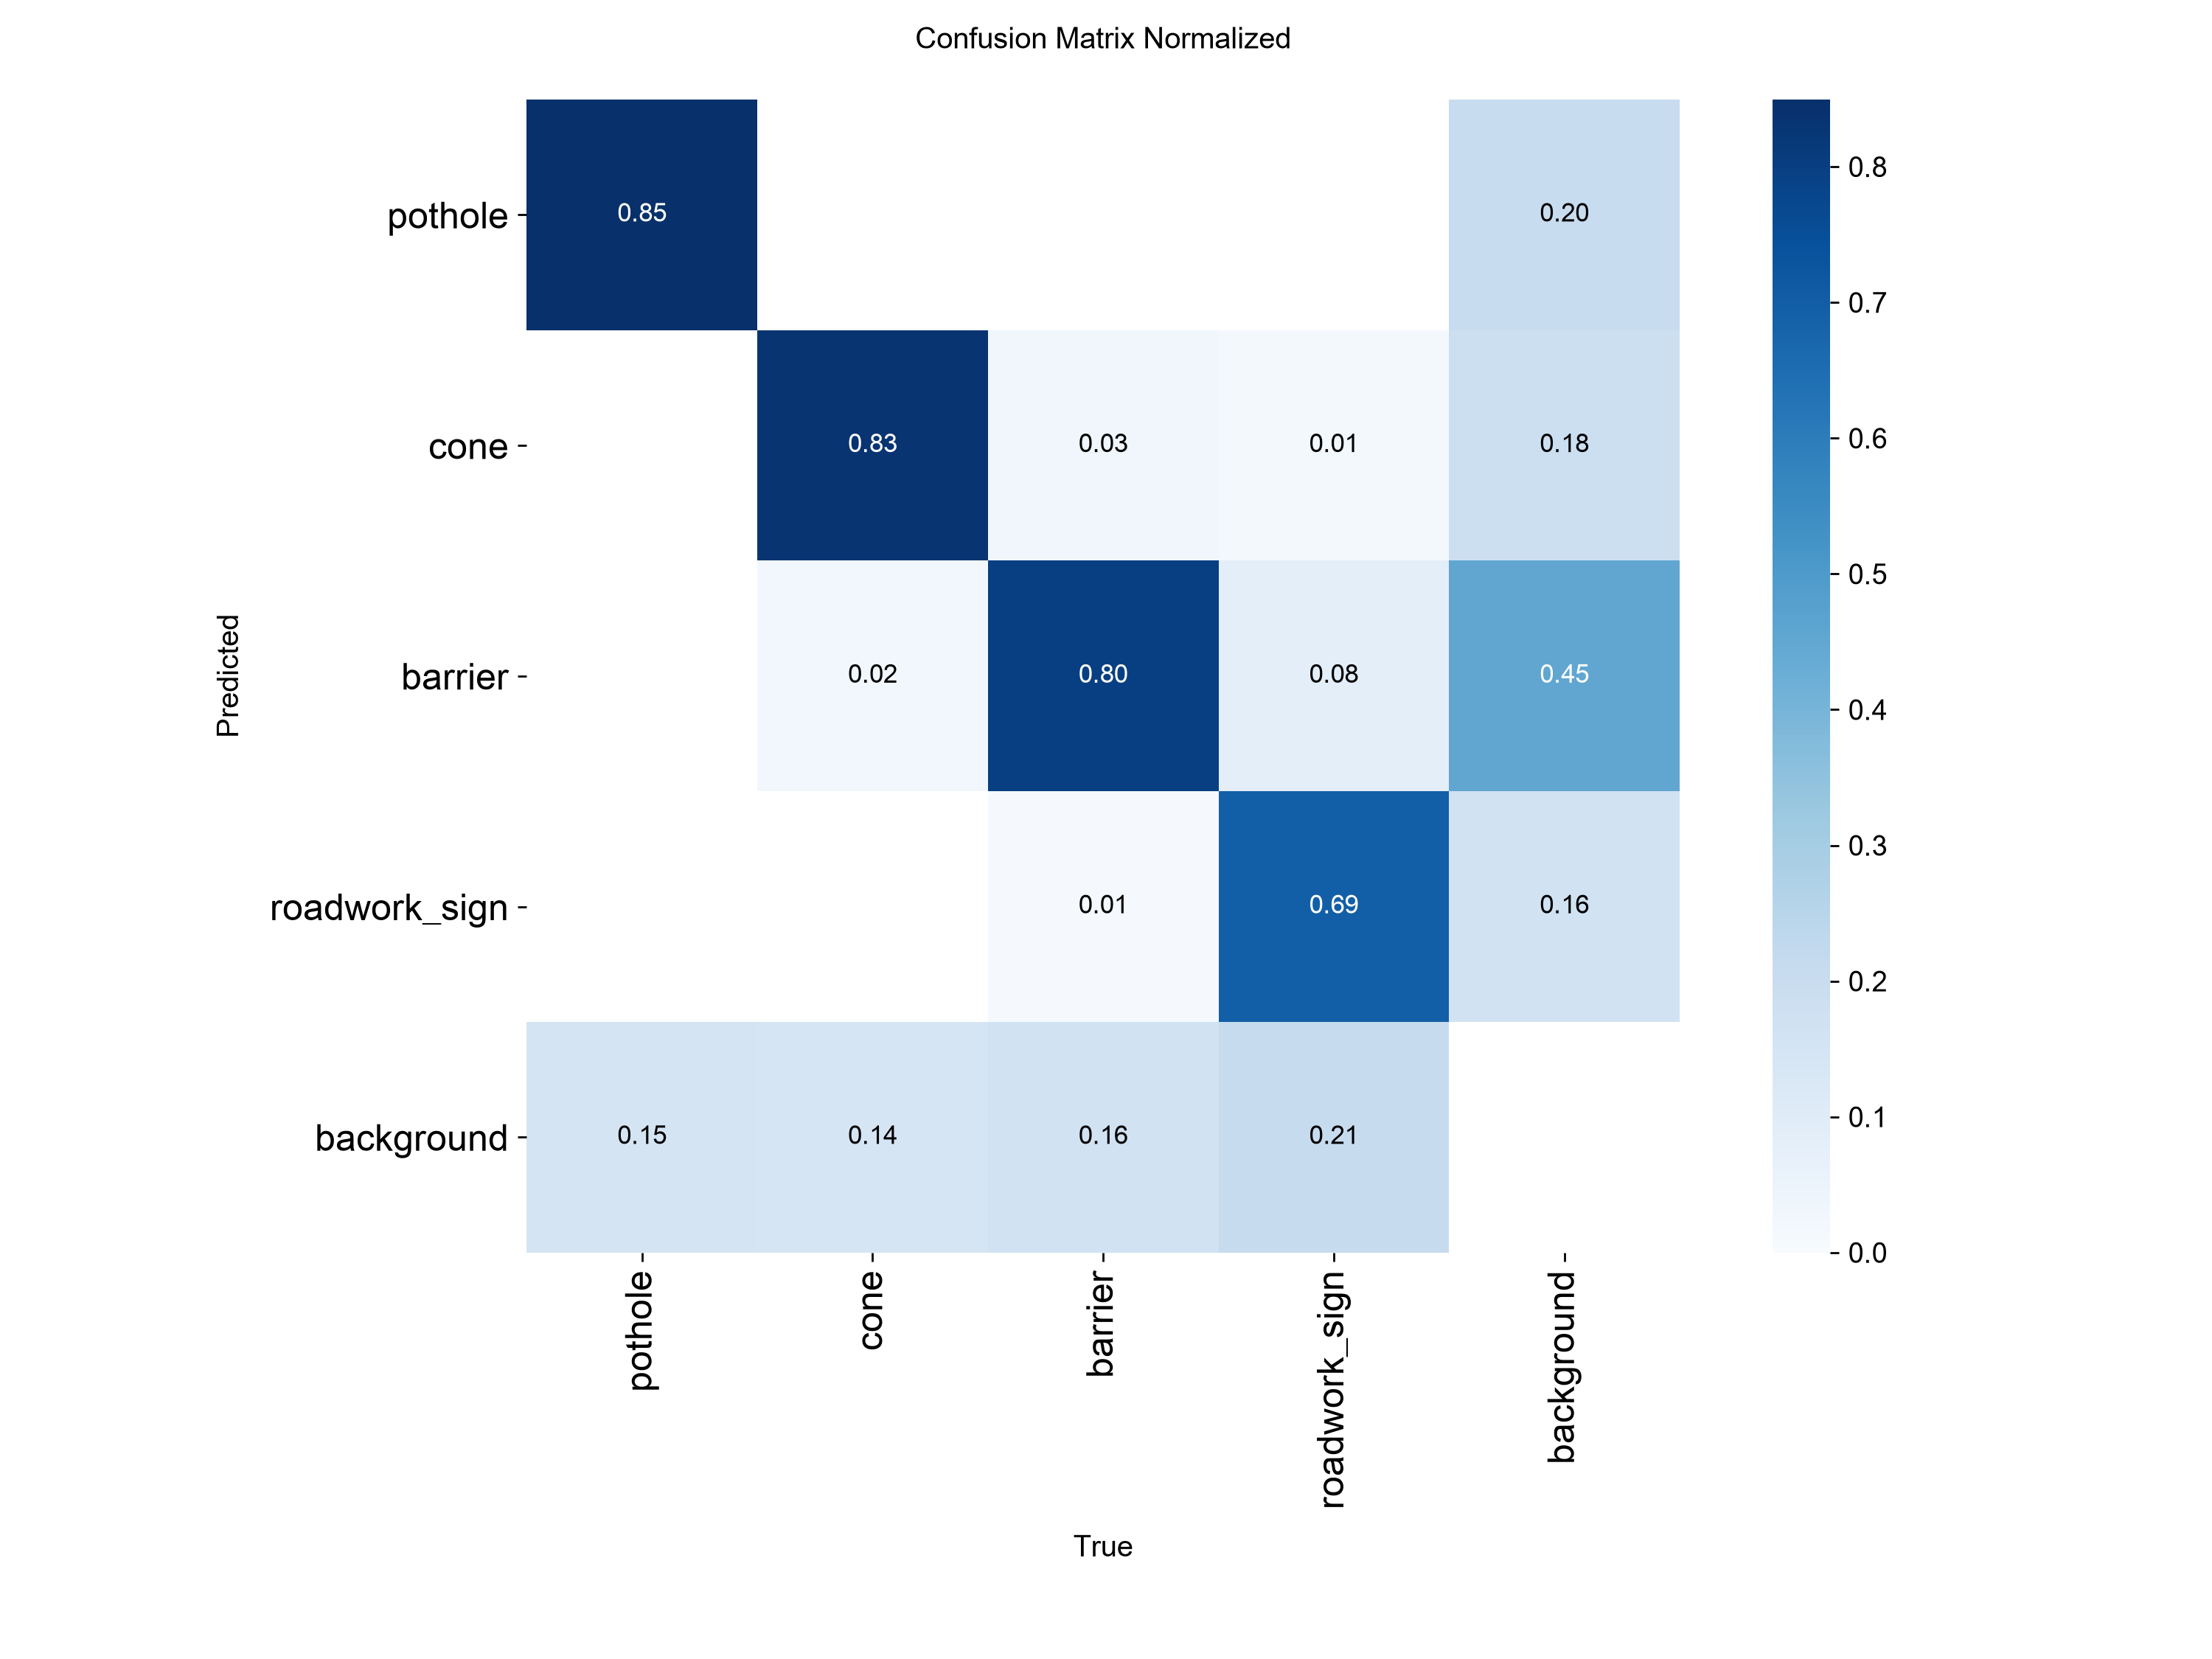

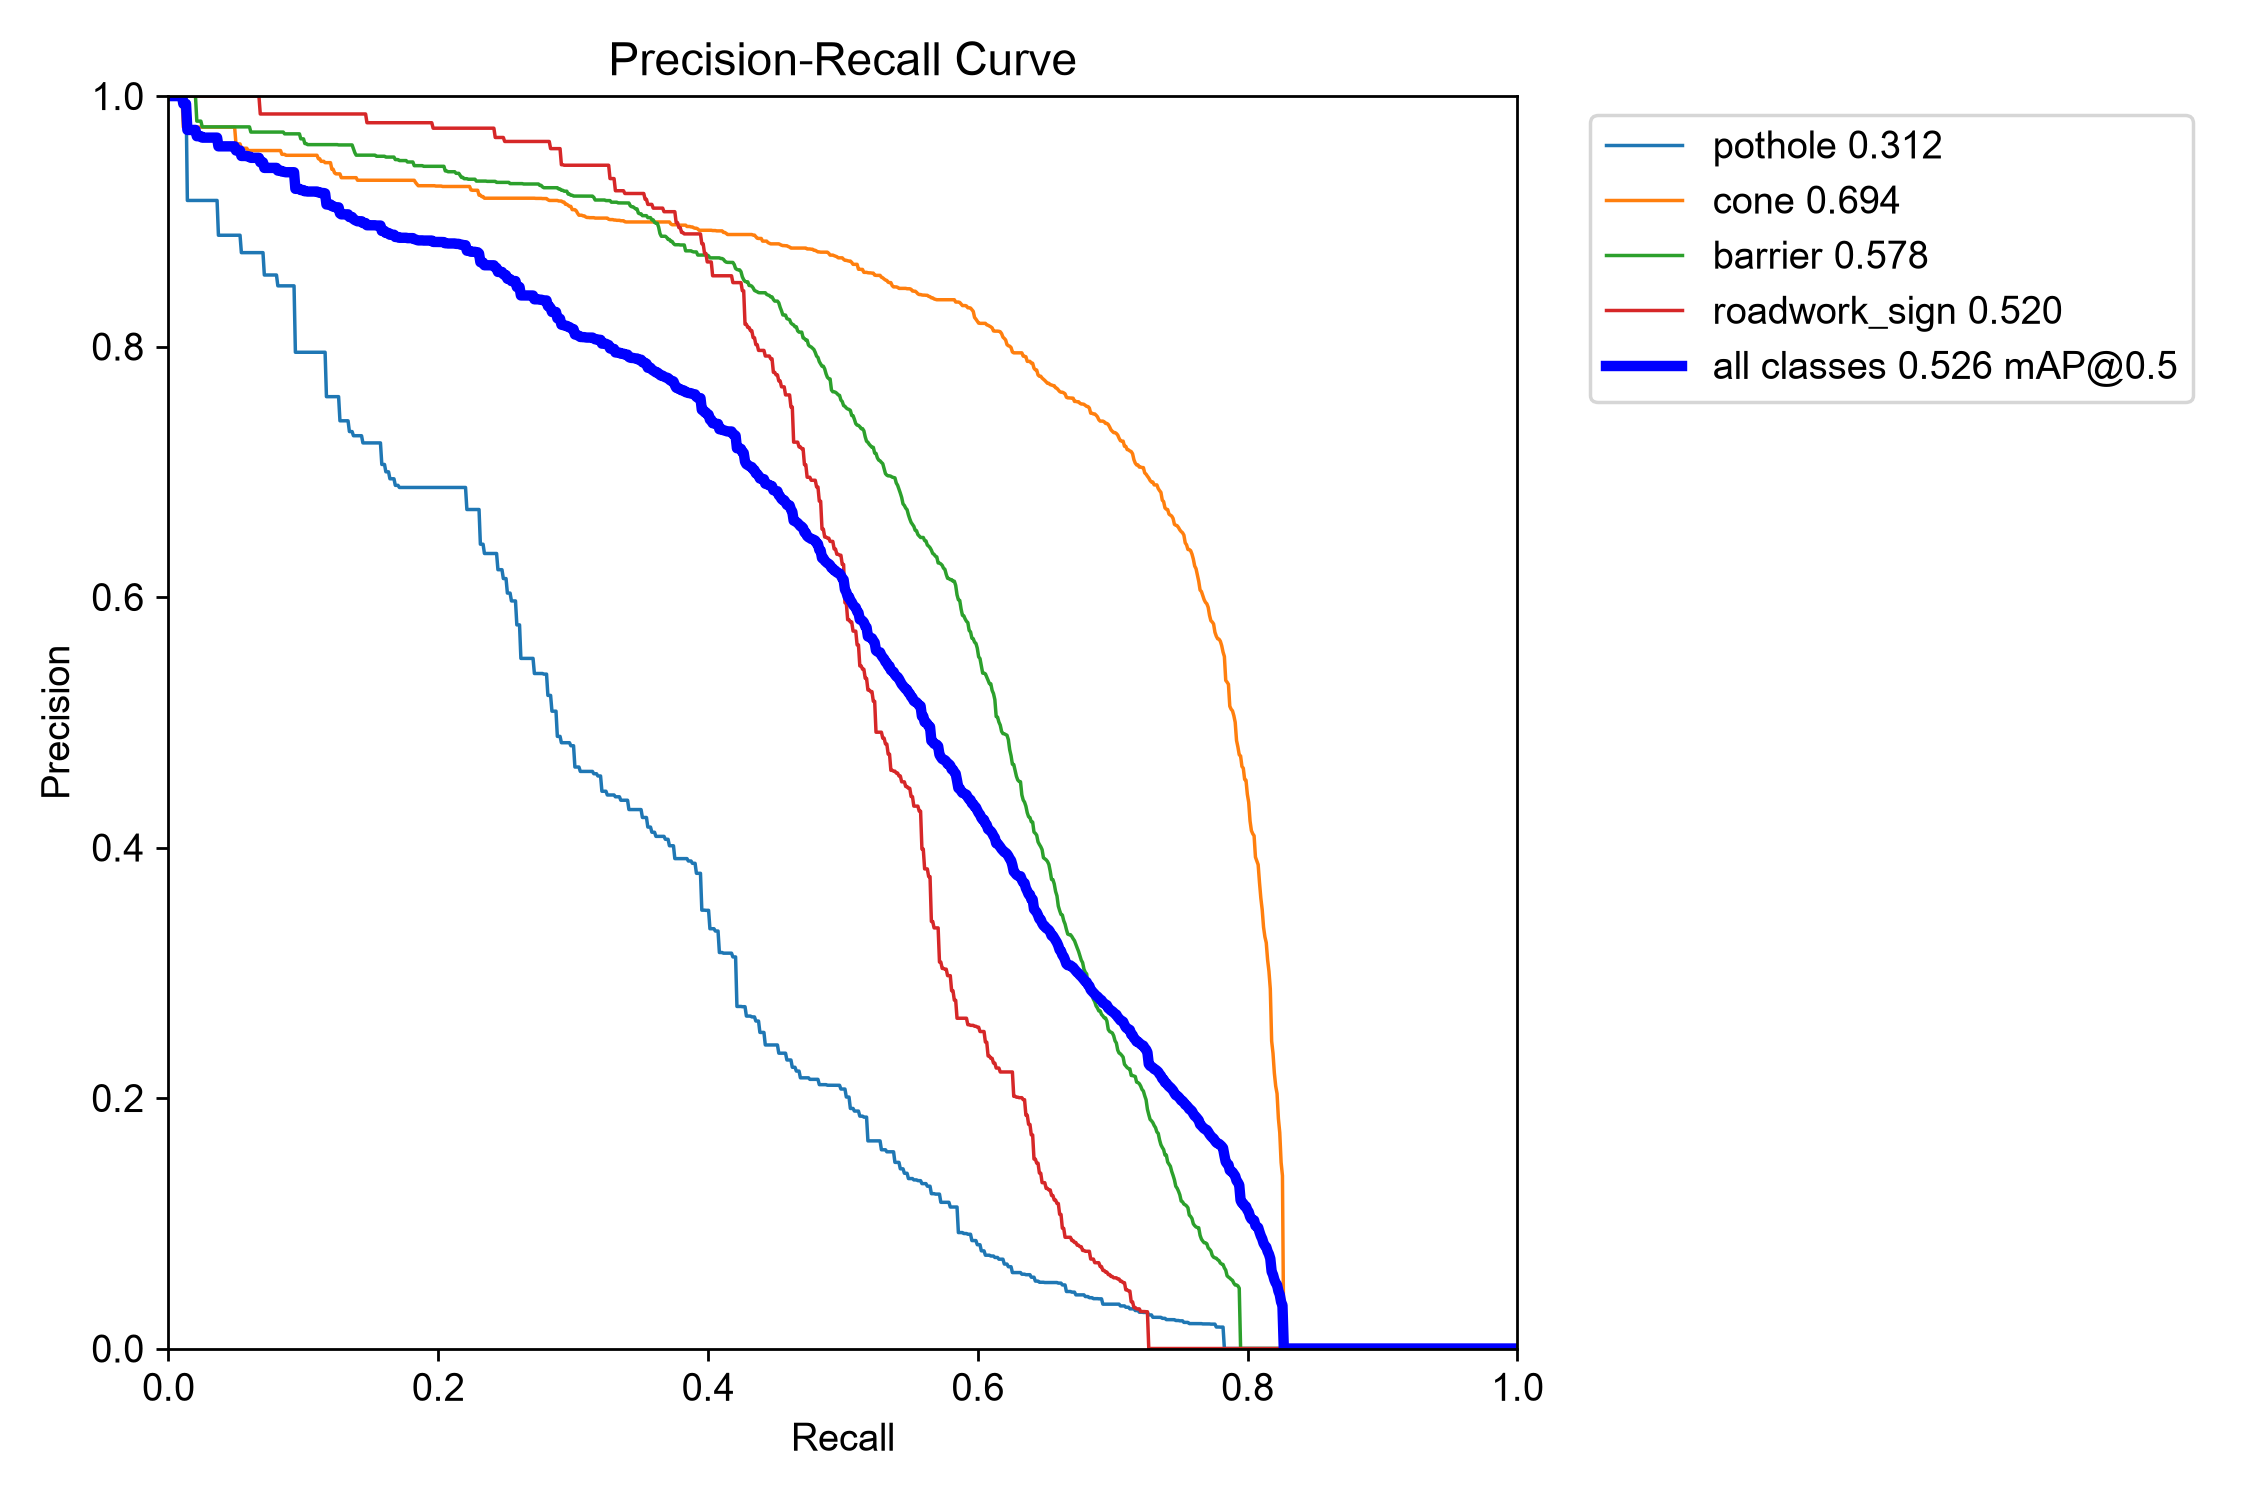

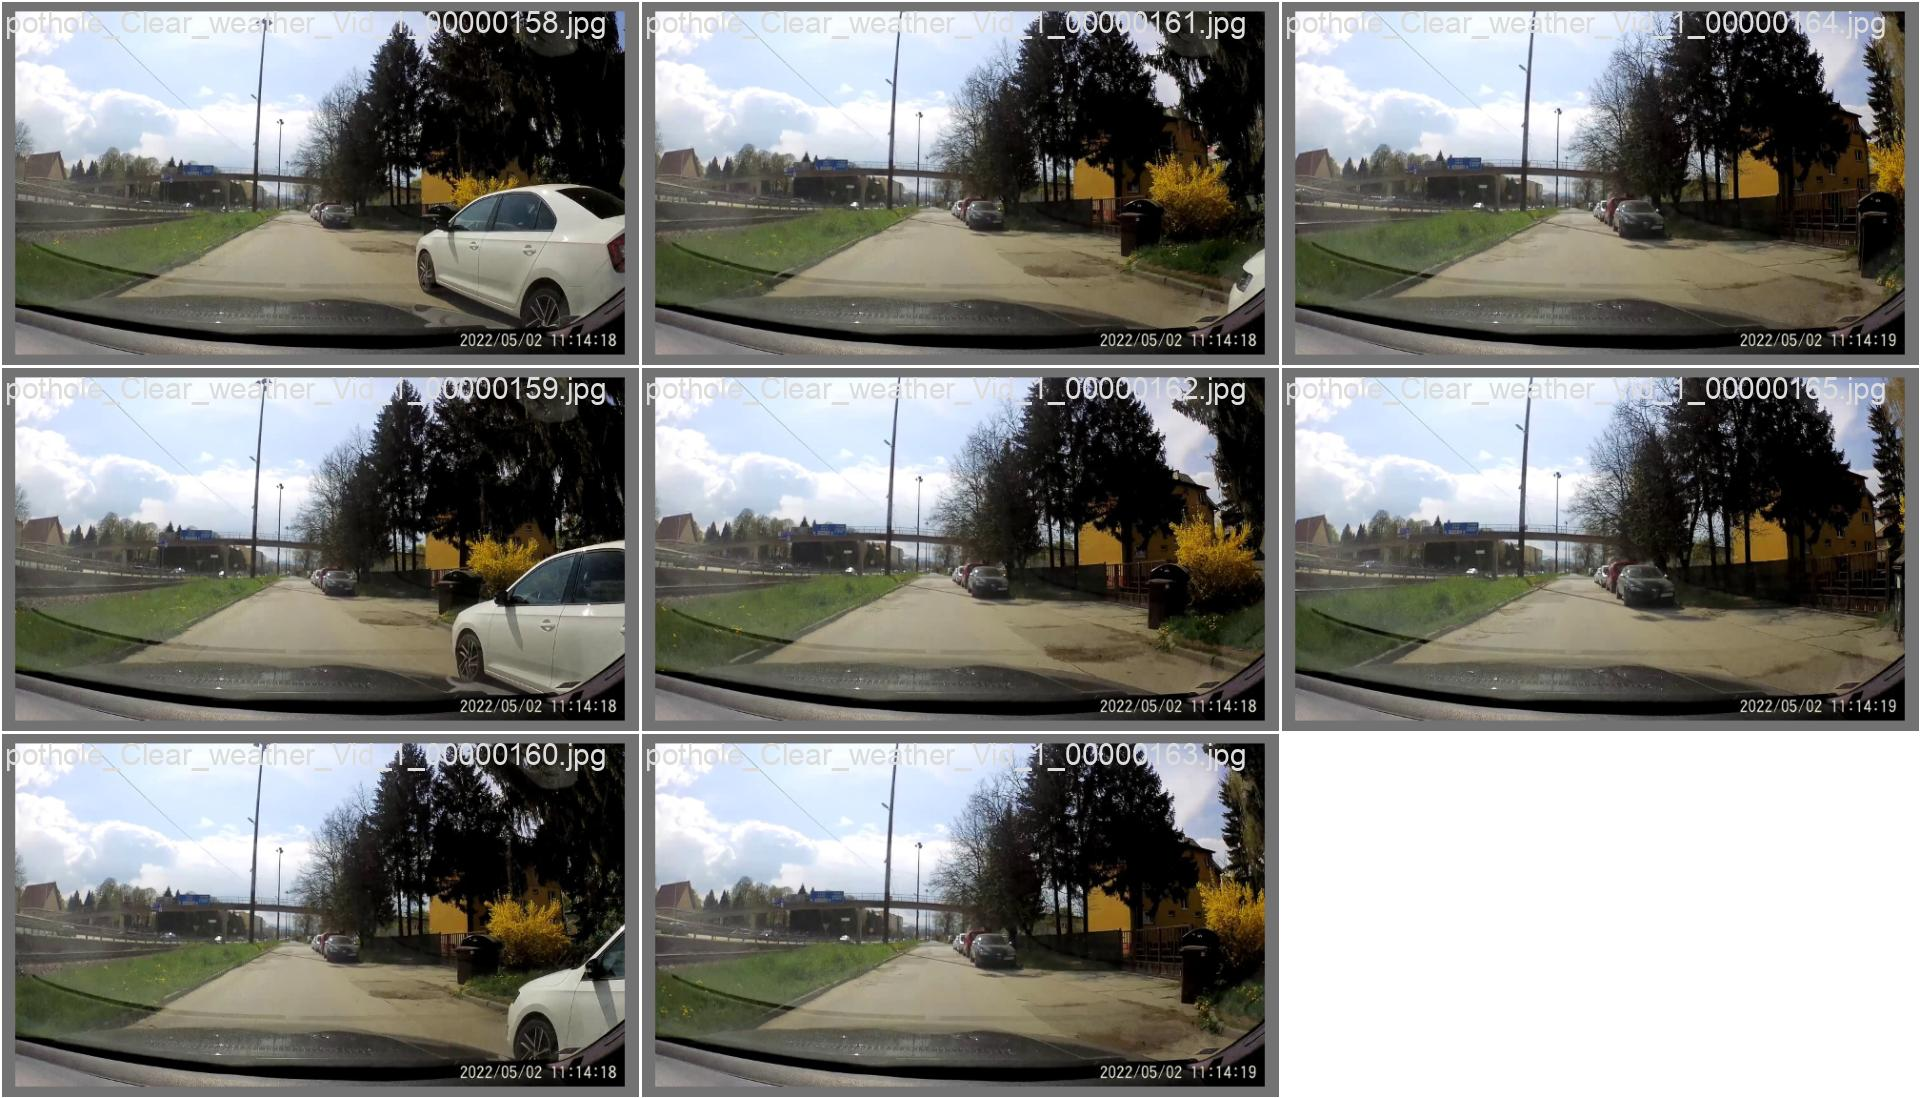

In [13]:
best = YOLO(BEST)
m = best.val(data=str(DS / "data.yaml"), split="test", imgsz=IMGSZ, batch=8, device=DEVICE, plots=True,
             project=str(RUNS), name="road_hazards_test", exist_ok=True)
P, R = float(m.box.mp), float(m.box.mr)
metrics = {"precision": round(P, 3), "recall": round(R, 3), "map50": round(float(m.box.map50), 3),
           "map50_95": round(float(m.box.map), 3), "f1": round(2 * P * R / max(P + R, 1e-9), 3),
           "inference_ms": round(float(m.speed["inference"]), 1)}
per_class = {CLASSES[int(c)]: round(float(ap), 3) for c, ap in zip(m.box.ap_class_index, m.box.ap50)}
cm = m.confusion_matrix.matrix                 # rows = predicted, cols = true (last = background)
confusion = {"labels": CLASSES + ["background"], "matrix": cm.T.astype(int).tolist()}   # rows = true
print(json.dumps(metrics, indent=1)); print("AP@50 per class:", per_class)
for f in ("confusion_matrix_normalized.png", "BoxPR_curve.png", "PR_curve.png", "val_batch0_pred.jpg"):
    p = RUNS / "road_hazards_test" / f
    if p.exists():
        display(Image(filename=str(p), width=800))

## 6 · Export for the dashboard (ONNX → real time on CPU, no PyTorch needed)
* `models/road_hazards.onnx` — our fine-tuned model
* `models/road_users.onnx` — the COCO-pretrained model (pedestrians, vehicles, animals)

In [14]:
hazards_onnx = Path(best.export(format="onnx", imgsz=IMGSZ, opset=17, simplify=True))
shutil.copy(hazards_onnx, MODELS / "road_hazards.onnx")
shutil.copy(BEST, MODELS / "road_hazards.pt")

users = YOLO(USERS_MODEL)                             # COCO-pretrained, used as-is
users_onnx = Path(users.export(format="onnx", imgsz=IMGSZ, opset=17, simplify=True))
shutil.copy(users_onnx, MODELS / "road_users.onnx")

# How the dashboard combines the two models: model class -> dashboard obstacle class
USERS_MAP = {"person": "pedestrian", "bicycle": "cyclist", "motorcycle": "vehicle", "car": "vehicle",
             "bus": "vehicle", "truck": "vehicle", "train": "vehicle",
             "dog": "animal", "cat": "animal", "horse": "animal", "cow": "animal", "sheep": "animal", "bird": "animal"}
profile = {
    "name": "Real road obstacles (2 models)",
    "models": [
        {"id": "road-users", "path": "models/road_users.onnx", "imgsz": IMGSZ, "conf": 0.40, "classes": USERS_MAP},
        {"id": "road-hazards", "path": "models/road_hazards.onnx", "imgsz": IMGSZ, "conf": 0.35,
         "classes": {"pothole": "pothole", "cone": "cone", "barrier": "barrier", "roadwork_sign": "roadwork"}},
    ],
}
(MODELS / "real_road.json").write_text(json.dumps(profile, indent=2))
print("exported:", [p.name for p in MODELS.glob("*.onnx")])

Ultralytics 8.4.184 🚀 Python-3.12.3 torch-2.14.1+cu132 CPU (Intel Core i7-10750H 2.60GHz)


💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO26s summary (fused): 120 layers, 9,466,728 parameters, 0 gradients, 20.8 GFLOPs

PyTorch: starting from '/workspace/training/runs/road_hazards/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 8, 8400) (19.4 MB)

ONNX: starting export with onnx 1.23.2 opset 17...
ONNX: slimming with onnxslim 0.1.98...
ONNX: export success ✅ 8.3s, saved as '/workspace/training/runs/road_hazards/weights/best.onnx' (36.4 MB)

Export complete (11.4s)
Results saved to /workspace/training/runs/road_hazards/weights/best.onnx
Predict:         yolo predict task=detect model=/workspace/training/runs/road_hazards/weights/best.onnx imgsz=640 
Validate:        yolo val task=detect model=/workspace/training/runs/road_hazards/weights/best.onnx imgsz=640 data=/datasets/road_hazards/data.yaml 
Visualize:       https://netron.app
Ultralytics 8.4.18

In [15]:
# Write the REAL evaluation numbers into the registry shown on the dashboard's AI models page
reg_path = MODELS / "registry.json"
registry = json.loads(reg_path.read_text())
n_train = n_img["train"]
hazards_entry = {
    "id": "road-hazards", "mode": "real", "name": "Road hazards detector",
    "framework": f"{MODEL.split('.')[0].upper()} fine-tuned (Ultralytics {ultralytics.__version__})",
    "version": "1.0", "trained": date.today().isoformat(), "input": f"{IMGSZ} × {IMGSZ}",
    "dataset": {"images": sum(n_img.values()), "split": f"{n_img['train']} / {n_img['val']} / {n_img['test']}",
                "sources": ["Potholes under challenging conditions (Bučko et al., Sensors 2022) — CC BY 4.0",
                            "ROADWork (Ghosh et al., ICCV 2025, CMU) — ODC-By 1.0"]},
    "example": False, "metrics_source": "held-out test split (this notebook)",
    "metrics": metrics, "per_class": per_class, "confusion": confusion,
    "training": {"epochs": EPOCHS_DONE, "minutes": round(TRAIN_MINUTES, 1),
                 "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu"},
}
users_entry = {
    "id": "road-users", "mode": "real", "name": "Road users detector",
    "framework": f"{USERS_MODEL.split('.')[0].upper()} COCO-pretrained (Ultralytics)", "version": "COCO",
    "trained": "pretrained", "input": f"{IMGSZ} × {IMGSZ}",
    "dataset": {"images": 118287, "split": "COCO train2017 / val2017",
                "sources": ["COCO 2017 (Lin et al., ECCV 2014) — CC BY 4.0 annotations"]},
    "example": False, "metrics_source": "not re-evaluated here — see Ultralytics' published COCO val2017 results",
    "metrics": {}, "per_class": {}, "classes_used": sorted(set(USERS_MAP.values())),
}
others = [m for m in registry["models"] if m.get("id") not in ("real-road-v1", "road-hazards", "road-users")]
registry["models"] = [users_entry, hazards_entry] + others
reg_path.write_text(json.dumps(registry, indent=2, ensure_ascii=False))
print("registry updated")

registry updated


## 7 · Real dashcam demo clips (Wikimedia Commons)
Short 720p clips are cut directly from the remote files with ffmpeg (only the needed part is downloaded).

In [16]:
# The clip list and the cutting code live in fetch_demo_clips.py, so they can be re-run on their own:
#   docker compose --profile train run --rm trainer python fetch_demo_clips.py
import fetch_demo_clips
if FETCH_DEMO_VIDEOS:
    fetch_demo_clips.TEST_IMAGES = DS / "images" / "test"
    fetch_demo_clips.main()

# Demo clips — sources and licences

- `01_city_krakow.mp4` — City Driving 4K – Kraków Poland 2024 · Relaxing Roads · CC BY 3.0
- `02_barricades.mp4` — Dash cam footage shows driver ignoring barricades · Devinn Taufner · Public domain
- `03_lane_blocked.mp4` — Bypass of a traffic accident section · Public domain
- `04_pothole_street.mp4` — Cars Moving into pothole · Amuzujoe · CC BY-SA 4.0
- `04b_pothole_kumasi.mp4` — Pothole (Kumasi) · Amuzujoe · CC BY-SA 4.0
- `05_potholes_test_frames.mp4` — held-out test frames of the Potholes dataset (Bučko et al., Sensors 2022) · CC BY 4.0


## 8 · Sanity check: both models on a demo frame

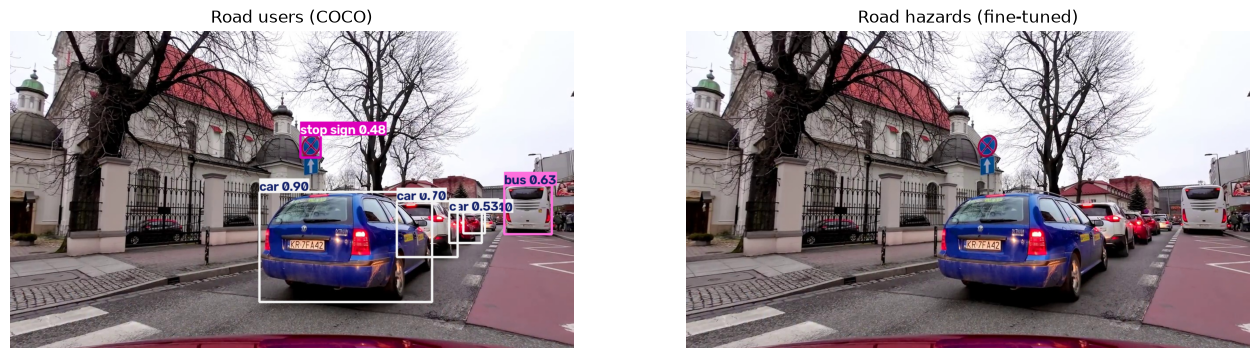

All done. Restart the dashboard:  docker compose restart dashboard


In [17]:
clip = sorted(DEMO.glob("*.mp4"))
frame_path = DEMO / "_check.jpg"
if clip:
    cap = cv2.VideoCapture(str(clip[0])); cap.set(cv2.CAP_PROP_POS_FRAMES, 150); ok, frame = cap.read(); cap.release()
    if ok:
        cv2.imwrite(str(frame_path), frame)
        a = users.predict(str(frame_path), conf=0.4, verbose=False)[0].plot()
        b = best.predict(str(frame_path), conf=0.35, verbose=False)[0].plot()
        fig, axes = plt.subplots(1, 2, figsize=(16, 5))
        axes[0].imshow(a[..., ::-1]); axes[0].set_title("Road users (COCO)"); axes[0].axis("off")
        axes[1].imshow(b[..., ::-1]); axes[1].set_title("Road hazards (fine-tuned)"); axes[1].axis("off")
        plt.show()
        frame_path.unlink()
print("All done. Restart the dashboard:  docker compose restart dashboard")